# 2 · GW strain data and instrument noise

**Goals:** inspect detector strain; estimate noise power spectral density (PSD); Pre-conditioning the GW data, understand whitening.

We use public **GW150914** strain data from H1 and L1 (GPS event time $1126259462.4$).

If the data hasn't already been downloaded, run from the repository root:

```bash
python download_data.py
```

This downloads 64 seconds of strain around GW150914 from GWOSC and creates:

```
data/
  GW150914_H1_4096Hz_64s.gwf
  GW150914_L1_4096Hz_64s.gwf
```

These are genuine gravitational-wave frame files containing the unfiltered 4096 Hz strain channel (`H1:GWOSC-4KHZ_R1_STRAIN` or `L1:GWOSC-4KHZ_R1_STRAIN`) and timestamps. During analysis we apply highpass filter and resample to 2048 Hz.

*“Will you see a black-hole merger in the raw time series?”* before plotting.


In [1]:
from pathlib import Path
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.signal.windows import hann
from pycbc.frame import read_frame
from pycbc.filter import highpass, resample_to_delta_t
from pycbc.psd import welch, interpolate, inverse_spectrum_truncation

/home/abhishek.sharma/miniconda3/envs/gw-env/lib/python3.11/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


In [2]:
GPS = 1126259462.4  # GW150914 geocentric GPS time
SAMPLING_FREQ = 2048  # analysis sampling frequency (Hz)
DURATION = 64
DATA_DIR = Path('data')

# Also support launching Jupyter from inside the notebooks/ subdirectory.
if not DATA_DIR.is_dir() and Path('../data').is_dir():
    DATA_DIR = Path('../data')

def load_detector(ifo='H1'):

    """Read locally cached, unfiltered GWOSC strain and prepare it for analysis."""
    
    path = DATA_DIR / f'GW150914_{ifo}_4096Hz_64s.gwf'
    channel = f'{ifo}:GWOSC-4KHZ_R1_STRAIN'
    
    if not path.exists():
        raise FileNotFoundError(f'{path} not found. From the repository root run: python download_data.py')
    
    raw = read_frame(str(path), channel)
    highpassed = resample_to_delta_t(highpass(raw, 15.0), 1.0 / SAMPLING_FREQ)
    conditioned = highpassed.crop(2, 2)
    
    return conditioned

def estimate_psd(data, f_low=20):
    
    seg = 4 * SAMPLING_FREQ
    psd = welch(data, seg_len=seg, seg_stride=seg//2)
    
    return psd

# Function to whiten a frequency series `freqSeries` colored with `PSD`.
def whiten(freqSeries, PSD):

    PSD = interpolate(PSD, freqSeries.delta_f)
    PSD.data[np.where(PSD.data == 0)[0]] = 10**(-50)
    whiten_strain = (freqSeries / (PSD/freqSeries.delta_t/2) ** 0.5).to_timeseries()

    whiten_strain = whiten_strain[int(4 * freqSeries.sample_rate) : int(2*(len(freqSeries) - 1) - 4 * freqSeries.sample_rate)]

    return whiten_strain

plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11})


In [3]:
# Load H1 and L1 strain data
h1 = load_detector('H1')
l1 = load_detector('L1')

# Print data information
for ifo, strain in [('H1', h1), ('L1', l1)]:
    print(f'{ifo}:')
    print('  Duration (s):', len(strain) * strain.delta_t)
    print('  Sampling rate (Hz):', strain.sample_rate)
    print('  Start GPS:', strain.start_time)

H1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432
L1:
  Duration (s): 60.0
  Sampling rate (Hz): 2048.0
  Start GPS: 1126259432


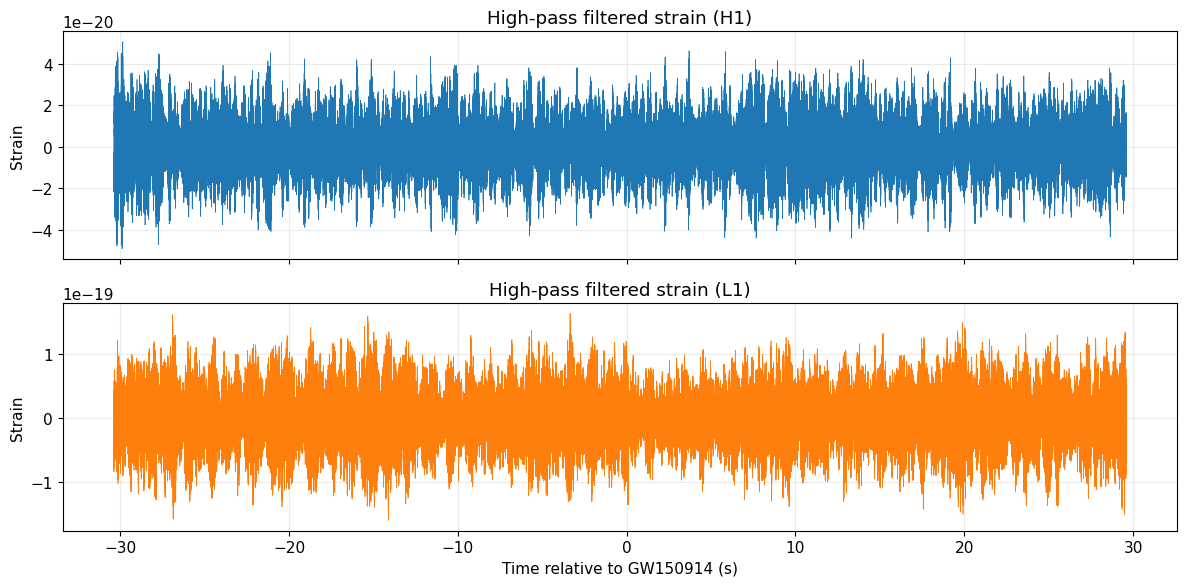

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].plot(h1.sample_times - GPS, h1, lw=0.5)
axes[0].set_ylabel('Strain')
axes[0].set_title('High-pass filtered strain (H1)')
axes[0].grid(alpha=0.25)

axes[1].plot(l1.sample_times - GPS, l1, lw=0.5, color='tab:orange')
axes[1].set_ylabel('Strain')
axes[1].set_title('High-pass filtered strain (L1)')
axes[1].set_xlabel('Time relative to GW150914 (s)')
axes[1].grid(alpha=0.25)

# axes[1].set_xlim(-5, 5)

plt.tight_layout()
plt.show()

Let's look at its frequency content.

Text(0, 0.5, '$|\\tilde{s}(f)|$ [1/Hz]')

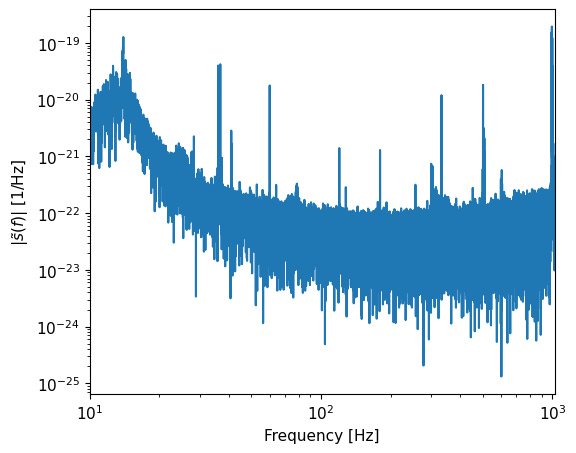

In [5]:
h1_f = h1.to_frequencyseries()
l1_f = l1.to_frequencyseries()

plt.figure(figsize = (6, 5))
plt.loglog(h1_f.sample_frequencies, np.abs(h1_f))
plt.xlim(10, SAMPLING_FREQ/2)
plt.xlabel('Frequency [Hz]')
plt.ylabel(r'$|\tilde{s}(f)|$ [1/Hz]')

This looks noisy. Maybe because of spectral leakage? We forgot tapering the sharp edges!

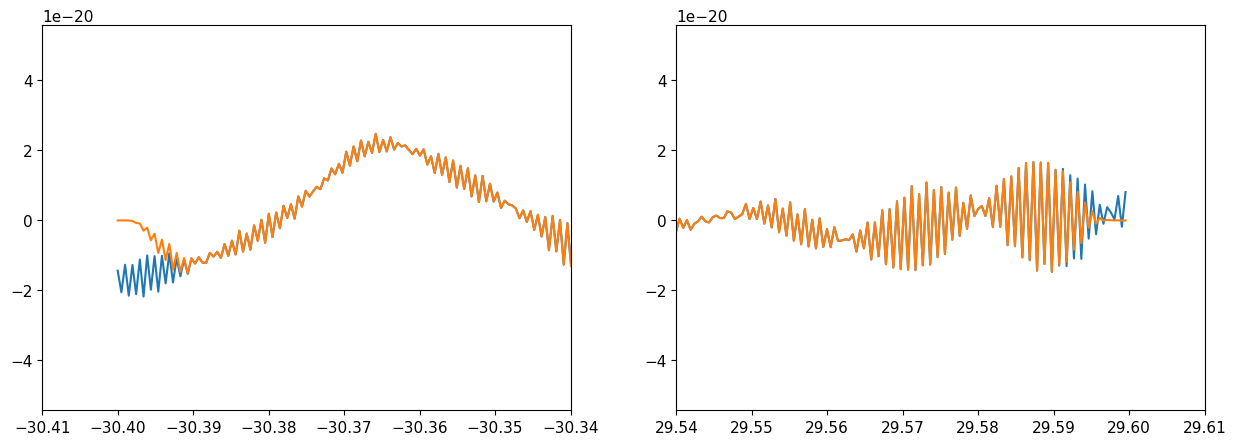

In [6]:
h1_taper = h1.taper_timeseries(location = 'TAPER_STARTEND')
h1_f_taper = h1_taper.to_frequencyseries()

fig, axes = plt.subplots(1, 2, figsize = (15, 5))
axes[0].plot(h1.sample_times - GPS, h1)
axes[0].plot(h1_taper.sample_times - GPS, h1_taper)
axes[0].set_xlim(-30.41, -30.34)

axes[1].plot(h1.sample_times - GPS, h1)
axes[1].plot(h1_taper.sample_times - GPS, h1_taper)
axes[1].set_xlim(29.54, 29.61)
plt.show()

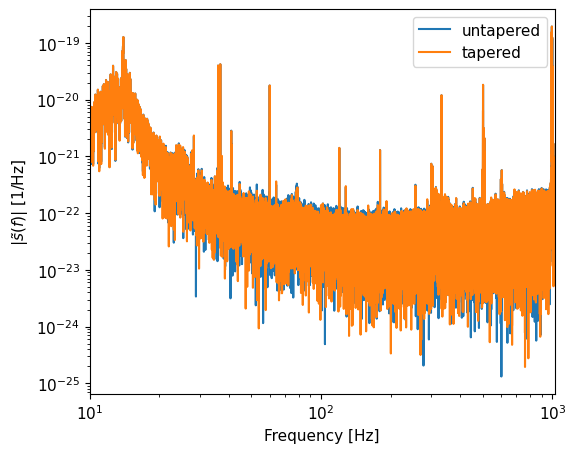

In [7]:
plt.figure(figsize = (6, 5))
plt.loglog(h1_f.sample_frequencies, np.abs(h1_f), label = 'untapered')
plt.loglog(h1_f_taper.sample_frequencies, np.abs(h1_f_taper), label = 'tapered')
plt.xlim(10, SAMPLING_FREQ/2)
plt.legend()
plt.xlabel('Frequency [Hz]')
plt.ylabel(r'$|\tilde{s}(f)|$ [1/Hz]')
plt.show()

Still looks noisy...

### [Power Spectral Density (PSD)](https://en.wikipedia.org/wiki/Spectral_density)

The **power spectral density (PSD)**, $S_n(f)$, describes noise power per hertz and has units $1/\mathrm{Hz}$ for dimensionless strain.

Given a data stretch of length $T$, one definition for the PSD of stationary noise $S_n(f)$ is
$$ S_{n}(f) = \lim_{T \rightarrow +\infty} \frac{2}{T} \langle \left| \tilde{n}_{T}(f) \right|^{2} \rangle$$
meaning that the PSD measures the spectral shape of the noise time series.

## Estimating the power spectral density

A standard way to do this PSD estimation is [Welch's estimation method](https://en.wikipedia.org/wiki/Welch%27s_method).

Welch's method divides the time series into overlapping pieces, Fourier-transforms them, and averages their periodograms. Longer segments provide finer frequency resolution, but fewer averages for a fixed data duration.

### Welch's method: 

A single finite-duration Fourier transform gives a **periodogram**, $|\tilde n(f)|^2$. It fluctuates considerably from one realization of noise to another. Welch's method reduces these fluctuations by averaging periodograms from shorter (usually overlapping) stretches of data.

For a segment containing $N$ samples, the duration is $T=N/f_s$. After applying a window $w_j$, we normalize by the mean-square window amplitude $U=N^{-1}\sum_j w_j^2$. The window-corrected periodogram is

$$
\widehat S_k(f_m)
=
\frac{2}{TU}
\left|
\Delta t \sum_{j=0}^{N-1}
n_j w_j e^{-2\pi i mj/N}
\right|^2.
$$

Using $\Delta t=1/f_s$, $T=N/f_s$, and $U=N^{-1}\sum_j w_j^2$, this becomes

$$
\boxed{
\widehat S_k(f_m)
=
\frac{2}{f_s\sum_{j=0}^{N-1}w_j^2}
\left|
\sum_{j=0}^{N-1}
n_j w_j e^{-2\pi i mj/N}
\right|^2.
}
$$


Here $k$ labels the segment. Dividing by $\sum w_j^2$ corrects for the power removed by the window. For rectangular windows, this reduces to $\widehat S=2|\tilde n_T|^2/T$, with $\tilde n_T\approx \Delta t\,\mathrm{FFT}(n)$.

The Welch estimate averages these individual periodograms:

$$\widehat S_{\rm Welch}(f_m)=\frac{1}{K}\sum_{k=1}^{K}\widehat S_k(f_m).$$

We'll use **4-second Hann-windowed segments with 50% overlap**. The window reduces spectral leakage; averaging suppresses random fluctuations.

In [8]:
def welch_psd(strain, segment_seconds=4, overlap=0.5):
    
    """Compute a one-sided, mean-averaged Welch PSD from a time series."""

    x = np.asarray(strain, dtype=float)
    fs = float(strain.sample_rate)
    nperseg = int(round(segment_seconds * fs))
    step = int(round(nperseg * (1 - overlap)))

    if not (0 <= overlap < 1):
        raise ValueError('overlap must be between 0 and 1')
    if nperseg > len(x) or nperseg < 2 or step < 1:
        raise ValueError('Invalid segment length or overlap')

    window = hann(nperseg, sym=False)
    normalization = fs * np.sum(window**2)
    starts = np.arange(0, len(x) - nperseg + 1, step)
    periodograms = []

    for start in starts:
        segment = x[start:start + nperseg]
        segment = segment - np.mean(segment)  # remove segment DC offset
        fft = np.fft.rfft(segment * window)
        psd_segment = np.abs(fft)**2 / normalization

        # Convert two-sided power to a one-sided PSD.
        if nperseg % 2 == 0:
            psd_segment[1:-1] *= 2  # exclude DC and Nyquist
        else:
            psd_segment[1:] *= 2   # exclude only DC
        periodograms.append(psd_segment)

    frequencies = np.fft.rfftfreq(nperseg, d=1/fs)
    periodograms = np.array(periodograms)
    mean_psd = np.mean(periodograms, axis=0)
    return frequencies, periodograms, mean_psd, starts, window

freq_manual, individual_psds, psd_manual, starts, window = welch_psd(h1)
print('Number of samples per segment:', len(window))
print('Number of segments:', len(starts))
print('Frequency resolution (Hz):', freq_manual[1] - freq_manual[0])

Number of samples per segment: 8192
Number of segments: 29
Frequency resolution (Hz): 0.25


**What does segmentation look like?** We illustrate the first four overlapping segments. 

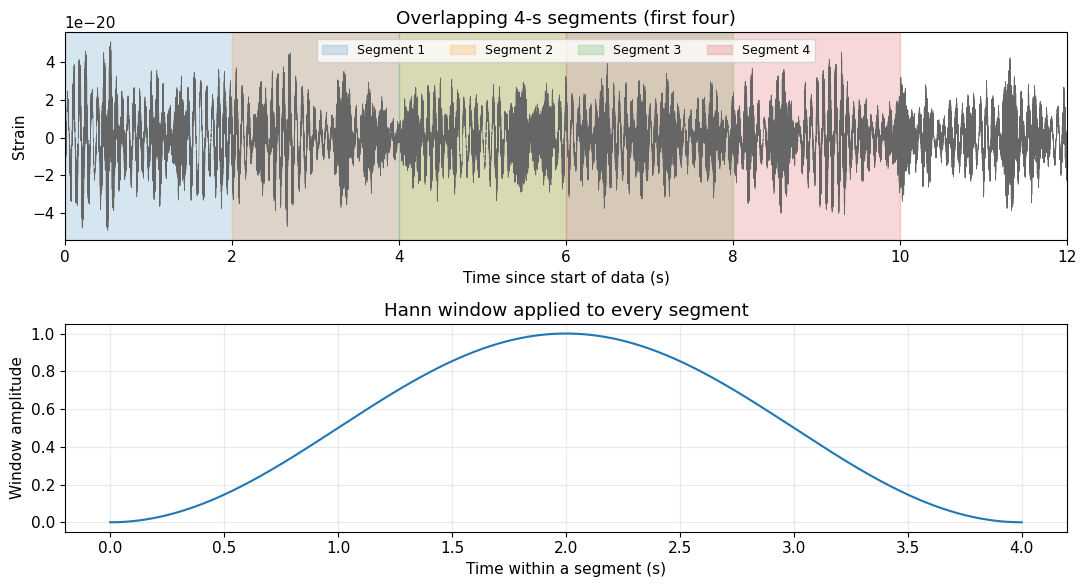

In [9]:
fs = float(h1.sample_rate)
nperseg = len(window)
step = starts[1] - starts[0] if len(starts) > 1 else nperseg

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
time = np.arange(len(h1)) / fs

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

axes[0].plot(time, np.asarray(h1), lw=0.4, color='0.4')
for i, start in enumerate(starts[:4]):
    axes[0].axvspan(start/fs, (start+nperseg)/fs, alpha=0.18, color = colors[i],
                    label=f'Segment {i+1}')
axes[0].set(xlim=(0, 12), xlabel='Time since start of data (s)',
            ylabel='Strain', title='Overlapping 4-s segments (first four)')
axes[0].legend(ncol=4, fontsize=9)

axes[1].plot(np.arange(nperseg)/fs, window)
axes[1].set(xlabel='Time within a segment (s)', ylabel='Window amplitude',
            title='Hann window applied to every segment')
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

**From individual periodograms to the average:** Each colored curve below is the PSD estimate from one 4-second segment. They fluctuate strongly. The thick black line averages **all** segments and is visibly smoother. To keep the amplitude range readable, we plot the *amplitude spectral density* (ASD), $\sqrt{S_n(f)}$, with units $1/\sqrt{\mathrm{Hz}}$. The averaging itself is performed on PSDs, **before** taking the square root.

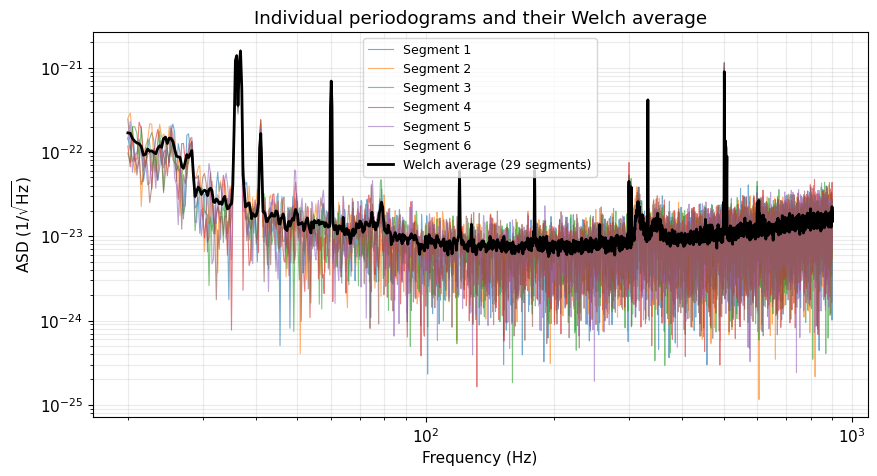

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
mask = (freq_manual >= 20) & (freq_manual <= 900)

for i in range(min(6, len(individual_psds))):
    ax.loglog(freq_manual[mask], np.sqrt(individual_psds[i, mask]),
              lw=0.8, alpha=0.6, label=f'Segment {i+1}')

ax.loglog(freq_manual[mask], np.sqrt(psd_manual[mask]),
          color='black', lw=2.0, label=f'Welch average ({len(starts)} segments)')
ax.set(xlabel='Frequency (Hz)', ylabel=r'ASD ($1/\sqrt{\mathrm{Hz}}$)',
       title='Individual periodograms and their Welch average')
ax.legend(fontsize=9)
ax.grid(True, which='both', alpha=0.25)
plt.show()

## Implementation in PyCBC

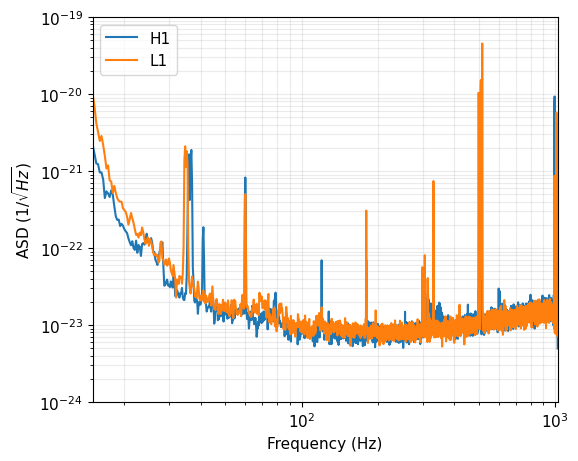

Frequency bin width (Hz): 0.25


In [11]:
strain = {}
strain['H1'] = h1
strain['L1'] = l1

psds = {}

for ifo in ["H1", "L1"]:
    seglen_sec = 4
    seglen = int(seglen_sec*SAMPLING_FREQ)
    psds[ifo] = welch(strain[ifo], seg_len= seglen, seg_stride=seglen//2)

fig,ax=plt.subplots(figsize = (6, 5))
ax.loglog(psds['H1'].sample_frequencies, np.sqrt(psds["H1"]), label = "H1")
ax.loglog(psds['L1'].sample_frequencies, np.sqrt(psds["L1"]), label = "L1")
ax.set(xlabel='Frequency (Hz)',ylabel=r'ASD ($1/\sqrt{Hz}$)', xlim=[15, 1024], ylim = [1e-24, 1e-19])
ax.grid(True,which='both',alpha=.25)
plt.legend()
plt.show()
print('Frequency bin width (Hz):',psds["H1"].delta_f)

In [12]:
h1_f.delta_f, psds["H1"].delta_f

(0.016666666666666666, 0.25)

**Exercise:** Try segments of 2, 4, and 8 s. Compare smoothness and narrow lines. Note: different window/averaging choices also matter.

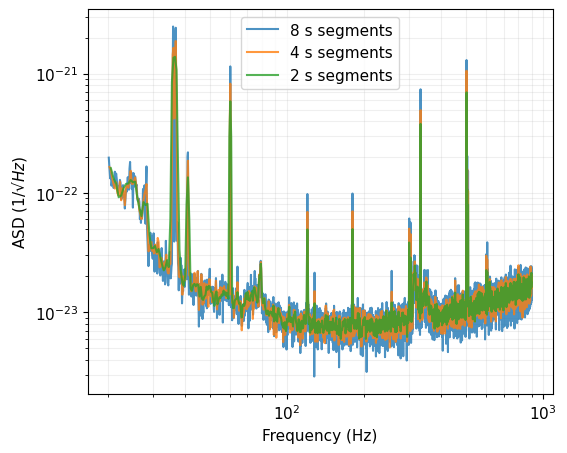

In [13]:
fig,ax=plt.subplots(figsize = (6, 5))

for seconds in [8, 4, 2]:

    k=int(seconds*SAMPLING_FREQ)
    
    estimate=welch(h1, seg_len=k, seg_stride=k//2)
    f=estimate.sample_frequencies
    sel=(f>20)&(f<900)

    ax.loglog(f[sel],np.sqrt(estimate[sel]),label=f'{seconds} s segments',alpha=.8)
    
ax.set_xlabel('Frequency (Hz)')
plt.ylabel('ASD ($1/√Hz$)')
plt.legend()
plt.grid(alpha=.2,which='both')
plt.show()

## Whitening: flattening the noise spectrum
Whitening divides by the estimated amplitude spectrum (with appropriate Fourier normalization), making frequency bands contribute more equally. Edge transients are common after filtering: always crop the edges before interpretation.

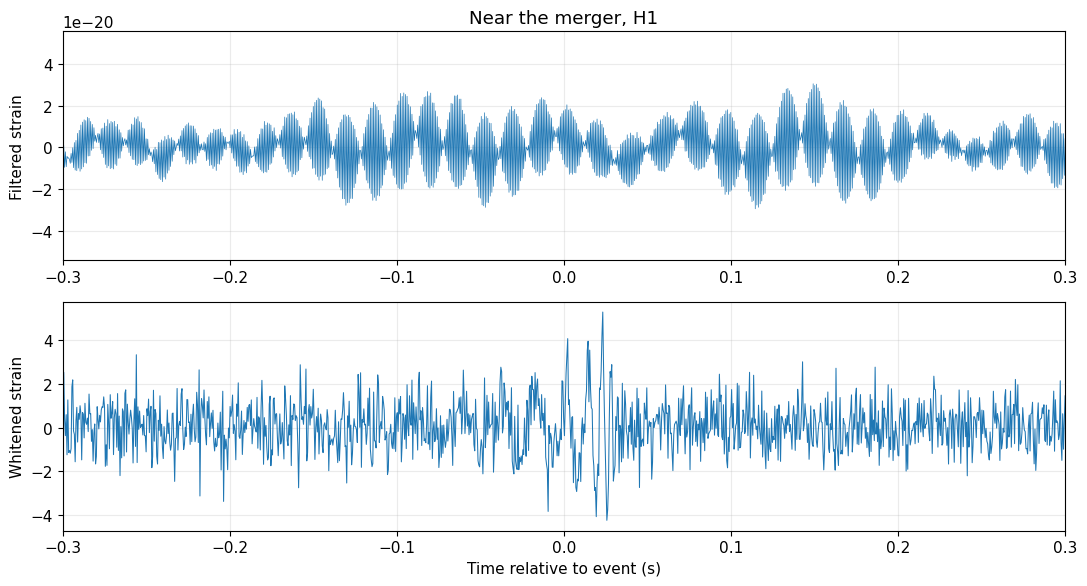

In [14]:
# whiten_h1 = h1.whiten(4, 4, low_frequency_cutoff=20)
# whiten_l1 = l1.whiten(4, 4, low_frequency_cutoff=20)

whiten_h1 = whiten(h1.taper_timeseries(location = 'TAPER_STARTEND').to_frequencyseries(), psds["H1"])
whiten_l1 = whiten(l1.taper_timeseries(location = 'TAPER_STARTEND').to_frequencyseries(), psds["L1"])

fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(h1.sample_times-GPS,h1,lw=0.5)
axs[0].set(xlim=(-.3,.3),ylabel='Filtered strain',title='Near the merger, H1')
axs[1].plot(whiten_h1.sample_times-GPS,whiten_h1,lw=0.75)
axs[1].set(xlim=(-.3,.3),xlabel='Time relative to event (s)',ylabel='Whitened strain')

for a in axs:
    a.grid(alpha=.25)

plt.tight_layout()
plt.show()

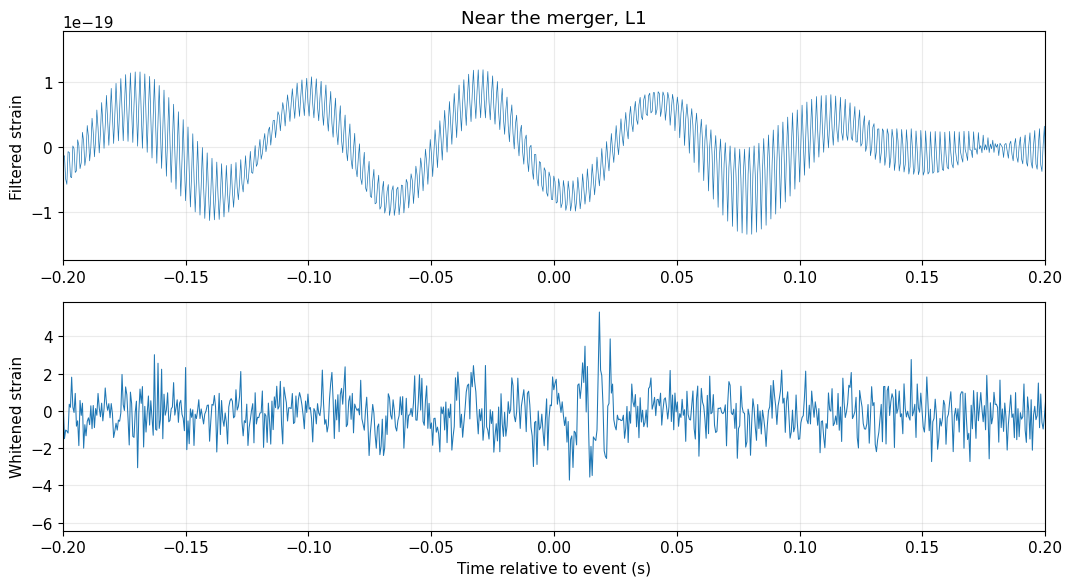

In [15]:
fig,axs=plt.subplots(2,1,figsize=(11,6))
axs[0].plot(l1.sample_times-GPS,l1,lw=0.5)
axs[0].set(xlim=(-.2,.2),ylabel='Filtered strain',title='Near the merger, L1')
axs[1].plot(whiten_l1.sample_times-GPS,whiten_l1,lw=0.75)
axs[1].set(xlim=(-.2,.2),xlabel='Time relative to event (s)',ylabel='Whitened strain')

for a in axs:
    a.grid(alpha=.25)

plt.tight_layout()
plt.show()

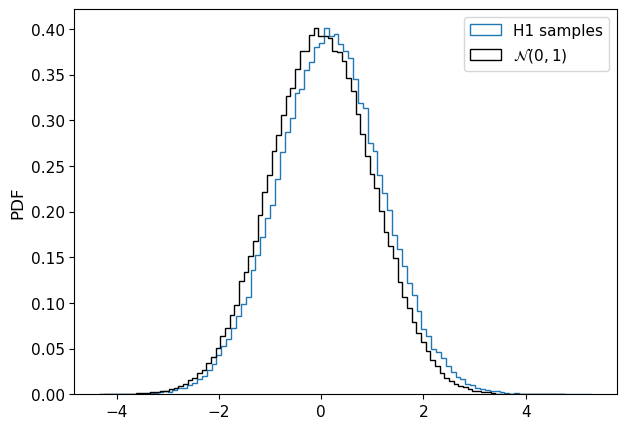

In [16]:
gaussian_samples = np.random.normal(loc=0, scale=1, size=100000)
whiten_h1_samples = whiten_h1.data

plt.figure(figsize = (7, 5))
_ = plt.hist(whiten_h1_samples, histtype = 'step', density = True, bins = 100, label = 'H1 samples')
_ = plt.hist(gaussian_samples, histtype='step', density = True, bins = 100, label = r'$\mathcal{N}(0,1)$', color = "k")
plt.ylabel('PDF', fontsize = 12)
plt.legend()
plt.show()